In [18]:
import torch
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

torch.manual_seed(42)


In [19]:
iris = load_iris()
X = iris.data
y = iris.target  # Only for evaluation, never for clustering

X = StandardScaler().fit_transform(X)
X = torch.tensor(X, dtype=torch.float32)

print("Dataset:", X.shape)

Dataset: torch.Size([150, 4])


In [20]:
def initialize_centroids(X, k):

    indices = torch.randperm(X.size(0))[:k]

    return X[indices].clone()

def calculate_distances(X, centroids):

    return torch.cdist(X, centroids)

In [21]:
def assign_clusters(X, centroids):
    distances = calculate_distances(X, centroids)
    return torch.argmin(distances, dim=1)


def update_centroids(X, clusters, centroids):
    new_centroids = []

    for k in range(len(centroids)):
        points = X[clusters == k]

        if len(points) == 0:
            # Reinitialize an empty cluster
            new_centroids.append(X[torch.randint(len(X), (1,)).item()])
        else:
            new_centroids.append(points.mean(dim=0))

    return torch.stack(new_centroids)

In [22]:
def kmeans(X, k, max_iterations=100, tolerance=1e-4):
    centroids = initialize_centroids(X, k)

    for iteration in range(max_iterations):
        clusters = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, clusters, centroids)

        shift = torch.norm(new_centroids - centroids)
        centroids = new_centroids

        if shift < tolerance:
            print(f"Converged after {iteration + 1} iterations")
            break

    clusters = assign_clusters(X, centroids)
    return clusters, centroids

In [23]:
clusters, centroids = kmeans(X, k=3)

print("Cluster counts:", torch.bincount(clusters))
print("Centroids shape:", centroids.shape)

Converged after 4 iterations
Cluster counts: tensor([ 16, 100,  34])
Centroids shape: torch.Size([3, 4])


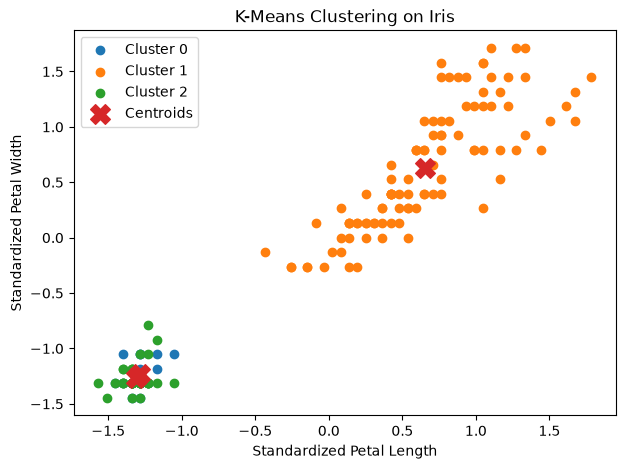

In [24]:
plt.figure(figsize=(7, 5))

for k in range(3):
    points = X[clusters == k]
    plt.scatter(points[:, 2], points[:, 3], label=f"Cluster {k}")

plt.scatter(
    centroids[:, 2],
    centroids[:, 3],
    marker="X",
    s=200,
    label="Centroids"
)

plt.xlabel("Standardized Petal Length")
plt.ylabel("Standardized Petal Width")
plt.title("K-Means Clustering on Iris")
plt.legend()
plt.show()

In [25]:
score = silhouette_score(X, clusters)
print(f"Silhouette Score: {score:.4f}")

Silhouette Score: 0.4838


Converged after 2 iterations
Converged after 2 iterations
Converged after 4 iterations
Converged after 7 iterations
Converged after 6 iterations
Converged after 7 iterations
Converged after 7 iterations
Converged after 5 iterations


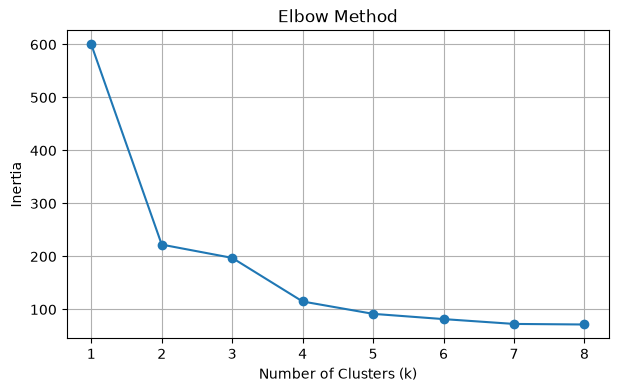

In [26]:
def calculate_inertia(X, clusters, centroids):
    total = 0.0

    for k in range(len(centroids)):
        points = X[clusters == k]
        if len(points) > 0:
            total += ((points - centroids[k]) ** 2).sum().item()

    return total


k_values = range(1, 9)
inertias = []

for k in k_values:
    torch.manual_seed(42)
    cluster_ids, centers = kmeans(X, k)
    inertias.append(calculate_inertia(X, cluster_ids, centers))

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid()
plt.show()